### Deep learning model training.
#### Note: 
1. when use unet, the bn parameters should be frozen using model.eval().  


In [1]:
import time
import torch
import random
import numpy as np 
import pandas as pd 
import torch.nn as nn
from glob import glob
from pyrsimg import imsShow
from processing import config
import matplotlib.pyplot as plt
import torch.nn.functional as F
from utils.utils import read_scenes
from torchvision.transforms import v2
from utils.data_aug import GaussianNoise
from utils.data_loader import SceneArraySet, PatchPathSet
from torchmetrics.classification import MulticlassJaccardIndex, BinaryAccuracy
from model import unet_timm, unet_swin_timm
from model import unet, unet_att, deeplabv3plus_mobilev2, swin_unet, watnet
from model.mamba_seg.mamba_seg import MambaSeg  


/home/xin/miniconda3/envs/watnet/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
patch_size = 512        ## patch size setting
patch_resize = None     ## patch resize setting
learning_rate = 1e-4     
batch_size = 4
device = torch.device('cuda:0')  


In [3]:
### traset
paths_tra_scene = config.paths_tra_scene
paths_tra_truth = config.paths_tra_truth
print(f'train_scenes: {len(paths_tra_scene)}')
## valset
paths_valset = sorted(glob(f'data/dset/val_patch/patch_{patch_size}/*'))  ## for model prediction 
print(f'vali_patch_{patch_size}: {len(paths_valset)}')


train_scenes: 172
vali_patch_512: 399


### dataset loading

In [4]:
scenes_arr, truths_arr = read_scenes(paths_tra_scene, paths_tra_truth) 
scene_truth_ls =  list(zip(scenes_arr, truths_arr))
scene_truth_ls = [np.concatenate([scene, truth[:, :, np.newaxis]], axis=-1) 
                                    for scene, truth in scene_truth_ls] 


In [5]:
transforms_tra = v2.Compose([
      # v2.ToImage(),
      v2.Resize((512, 512), antialias=True),
      v2.RandomCrop(size=(patch_size, patch_size), 
                    padding = 50, 
                    pad_if_needed=True,   # pad the image if it's smaller than the desired size
                    fill=0,
                    ),
      v2.RandomApply([v2.RandomRotation(degrees=15)], p=0.3),
      v2.RandomHorizontalFlip(p=0.3),
      v2.RandomVerticalFlip(p=0.3),
      v2.RandomApply([v2.GaussianNoise(mean=0.0, sigma=0.05)], p=0.3)  
       ])
# transforms_val = v2.Compose([
#       v2.Resize((256, 256), antialias=True),
#        ])


In [6]:
tra_dset = SceneArraySet(scene_truth_list = scene_truth_ls, transforms = transforms_tra)
val_dset = PatchPathSet(paths_valset=paths_valset, transforms=None)
### Create DataLoader
tra_loader = torch.utils.data.DataLoader(tra_dset, batch_size=batch_size, 
                                                shuffle=True, num_workers=4)
val_loader = torch.utils.data.DataLoader(val_dset, batch_size=batch_size, num_workers=5) 


#### Model training

In [9]:
### check model
# model = unet(num_bands=6)
# model = watnet(num_bands=6)
# model = unet_att(num_bands=6)
# model = deeplabv3plus_mobilev2(num_bands=6)
# model = swin_unet(img_size=512, num_bands=6, window_size=8)
## model with pretrained 
# model = unet_timm(num_bands=6, 
#                 #    backbone_name='efficientnet_b0', 
#                   # backbone_name='mobilenetv3_large_100',
#                   # backbone_name='resnet50',
#                   backbone_name = "vit_large_patch16_dinov3.sat493m",
#                   pretrained=False).to('cuda')

model = unet_swin_timm(num_bands=6, 
                         img_size = 512, 
                         backbone_name='swinv2_base_window8_256',
                         pretrained=True).to('cuda')
# model = MambaSeg(in_chans=6, 
#                     num_classes=1, 
#                     decoder_channels=32, 
#                     dims=96,  
#                     depths=(2, 2, 8, 2), 
#                     # backend='torch',
#                     backend='oflex', 
#                     pretrained = True
#                     ).to('cuda')
model_name = 'unet_pretrain_dinov3'  ## model name for saving  


In [ ]:
# input_tensor = torch.randn(2, 6, 512, 512)
input_tensor = torch.randn(2, 6, 512, 512, device='cuda')
output = model(input_tensor)
print(output.shape)


torch.Size([2, 1, 512, 512])


In [ ]:
### create loss and optimizer
bce_loss = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)  
# lr_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, \
#                                       mode='max', 
#                                       factor=0.5, 
#                                       patience=10,
#                                       min_lr=1e-5)


In [ ]:
sam_index = random.randrange(len(val_dset))
patch_val, truth_val = val_dset[sam_index]
def show_result(model, patch, truth):
    model.eval()
    device = next(model.parameters()).device
    patch, truth = patch.unsqueeze(0).to(device), truth.to(device)
    pred = model(patch) 
    pred = F.sigmoid(pred)   ## convert to probability
    ## convert to numpy and plot
    patch = patch[0].to('cpu').detach().numpy().transpose(1,2,0)            
    pred = pred[0].to('cpu').detach().numpy()
    truth = truth.to('cpu').detach().numpy()
    imsShow([patch, pred, truth],   
            clip_list = (2,0,0),
            img_name_list=['patch', 'pred', 'truth'], 
            color_bands_list=([3,2,2], 0, 0),                    
            figsize=(9, 2.5))
    plt.tight_layout() 
    plt.show()  

In [ ]:
'''------train loops------'''
def train_loops(model, loss_fn, 
                    optimizer, 
                    tra_loader, 
                    val_loader,  
                    epoches, 
                    device, 
                    lr_scheduler=None):
    loss_tra_loops, miou_tra_loops, oa_tra_loops = [], [], []
    loss_val_loops, miou_val_loops, oa_val_loops = [], [], []
    model = model.to(device)
    size_tra_loader = len(tra_loader)
    size_val_loader = len(val_loader)
    best_miou = 0.84
    epoches_i = []
    for epoch in range(epoches):
        start = time.time()
        loss_tra, loss_val = 0, 0
        '''-----train the model-----'''
        oa_tra = BinaryAccuracy().to(device)
        miou_tra = MulticlassJaccardIndex(num_classes=2, average="macro").to(device)
        model.train()   # training mode for dropout and batchnorm
        for x_batch, y_batch in tra_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            pred = model(x_batch)
            loss = loss_fn(pred, y_batch)
            loss.backward()
            optimizer.step()
            pred = (F.sigmoid(pred) > 0.5).float()
            miou_tra.update(pred, y_batch.long())
            oa_tra.update(pred, y_batch.long())
            loss_tra += loss.item()
        miou_tra_global = miou_tra.compute()
        oa_tra_global = oa_tra.compute()
        loss_tra_global = loss_tra/size_tra_loader
        miou_tra.reset(); oa_tra.reset()

        '''----- validation the model: time consuming -----'''
        oa_val = BinaryAccuracy().to(device)
        miou_val = MulticlassJaccardIndex(num_classes=2, average="macro").to(device)
        model.eval()
        if epoch > 100 and (epoch+1) % 2 == 0: 
            for x_batch, y_batch in val_loader:
                x_batch, y_batch = x_batch.to(device), y_batch.to(device)
                with torch.no_grad():
                    pred = model(x_batch)
                    loss = loss_fn(pred, y_batch)
                pred = (F.sigmoid(pred) > 0.5).float()
                miou_val.update(pred, y_batch.long())
                oa_val.update(pred, y_batch.long())
                loss_val += loss.item()
            miou_val_global = miou_val.compute()
            oa_val_global = oa_val.compute()
            loss_val_global = loss_val/size_val_loader
            miou_val.reset(); oa_val.reset()
            loss_tra_loops.append(loss_tra_global); miou_tra_loops.append(miou_tra_global.item()); oa_tra_loops.append(oa_tra_global.item())
            loss_val_loops.append(loss_val_global); miou_val_loops.append(miou_val_global.item()); oa_val_loops.append(oa_val_global.item())
            epoches_i.append(epoch)
            print(f'Ep{epoch}: tra-> Loss:{loss_tra_global:.3f},Oa:{oa_tra_global:.3f},Miou:{miou_tra_global:.3f}, '
                    f'val-> Loss:{loss_val_global:.4f},Oa:{oa_val_global:.4f}, Miou:{miou_val_global:.4f},time:{time.time()-start:.1f}s')
            ## save the best model
            if miou_val_global.item() > best_miou:
                best_miou = miou_val_global.item()       ## update best miou
                torch.save(model.state_dict(), f'model/trained/{model_name}_epoch_{epoch}_0{str(round(best_miou*10000))}.pth')
        else: 
            print(f'Ep{epoch}: tra-> Loss:{loss_tra_global:.3f},Oa:{oa_tra_global:.3f},Miou:{miou_tra_global:.3f}, \
                                time:{time.time()-start:.1f}s')
        if lr_scheduler: lr_scheduler.step(miou_tra_global)    ## if use lr_scheduler like ReduceLROnPlateau
        if (epoch+1)%50 == 0:
            sam_index = random.randrange(len(val_dset))
            patch_val, truth_val = val_dset[sam_index]
            show_result(model=model, patch=patch_val, truth=truth_val)
    metrics = {'epoch':epoches_i, 'tra_loss':loss_tra_loops, 'tra_oa': oa_tra_loops, 'tra_miou': miou_tra_loops,
                'val_loss': loss_val_loops, 'val_oa': oa_val_loops, 'val_miou': miou_val_loops}
    return metrics 

Ep0: tra-> Loss:0.370,Oa:0.819,Miou:0.409,                                 time:39.5s
Ep1: tra-> Loss:0.281,Oa:0.822,Miou:0.411,                                 time:39.3s
Ep2: tra-> Loss:0.258,Oa:0.821,Miou:0.411,                                 time:39.2s
Ep3: tra-> Loss:0.240,Oa:0.843,Miou:0.508,                                 time:39.3s
Ep4: tra-> Loss:0.224,Oa:0.910,Miou:0.732,                                 time:39.4s
Ep5: tra-> Loss:0.184,Oa:0.932,Miou:0.792,                                 time:39.3s
Ep6: tra-> Loss:0.173,Oa:0.937,Miou:0.813,                                 time:39.3s
Ep7: tra-> Loss:0.166,Oa:0.939,Miou:0.816,                                 time:39.3s
Ep8: tra-> Loss:0.151,Oa:0.942,Miou:0.828,                                 time:39.4s
Ep9: tra-> Loss:0.138,Oa:0.948,Miou:0.844,                                 time:39.3s
Ep10: tra-> Loss:0.127,Oa:0.954,Miou:0.857,                                 time:39.4s
Ep11: tra-> Loss:0.116,Oa:0.959,Miou:0.873,          

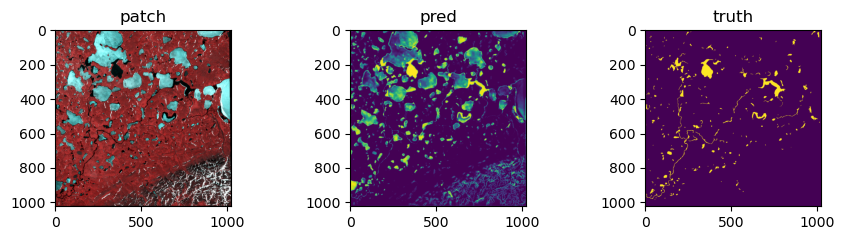

Ep50: tra-> Loss:0.071,Oa:0.973,Miou:0.913,                                 time:39.4s
Ep51: tra-> Loss:0.074,Oa:0.971,Miou:0.909,                                 time:39.5s
Ep52: tra-> Loss:0.066,Oa:0.975,Miou:0.920,                                 time:39.4s
Ep53: tra-> Loss:0.090,Oa:0.965,Miou:0.890,                                 time:39.4s
Ep54: tra-> Loss:0.076,Oa:0.971,Miou:0.907,                                 time:39.3s
Ep55: tra-> Loss:0.064,Oa:0.977,Miou:0.925,                                 time:39.4s
Ep56: tra-> Loss:0.064,Oa:0.976,Miou:0.923,                                 time:39.5s
Ep57: tra-> Loss:0.066,Oa:0.974,Miou:0.919,                                 time:39.3s
Ep58: tra-> Loss:0.064,Oa:0.975,Miou:0.921,                                 time:39.4s
Ep59: tra-> Loss:0.070,Oa:0.972,Miou:0.911,                                 time:39.4s
Ep60: tra-> Loss:0.061,Oa:0.977,Miou:0.925,                                 time:39.4s
Ep61: tra-> Loss:0.089,Oa:0.965,Miou:0.891,

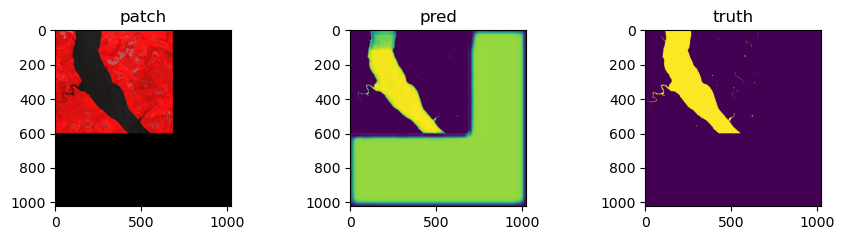

Ep100: tra-> Loss:0.048,Oa:0.982,Miou:0.942,                                 time:39.4s
Ep101: tra-> Loss:0.051,Oa:0.980,Miou:0.937, val-> Loss:0.1155,Oa:0.9604, Miou:0.8875,time:63.2s
Ep102: tra-> Loss:0.045,Oa:0.983,Miou:0.944,                                 time:39.3s
Ep103: tra-> Loss:0.048,Oa:0.982,Miou:0.942, val-> Loss:0.1176,Oa:0.9618, Miou:0.8902,time:63.1s
Ep104: tra-> Loss:0.049,Oa:0.981,Miou:0.938,                                 time:39.3s
Ep105: tra-> Loss:0.046,Oa:0.983,Miou:0.944, val-> Loss:0.1107,Oa:0.9636, Miou:0.8945,time:63.2s
Ep106: tra-> Loss:0.048,Oa:0.981,Miou:0.938,                                 time:39.3s
Ep107: tra-> Loss:0.047,Oa:0.982,Miou:0.943, val-> Loss:0.0911,Oa:0.9629, Miou:0.8924,time:63.1s
Ep108: tra-> Loss:0.049,Oa:0.982,Miou:0.942,                                 time:39.4s
Ep109: tra-> Loss:0.047,Oa:0.983,Miou:0.943, val-> Loss:0.0703,Oa:0.9726, Miou:0.9159,time:63.2s
Ep110: tra-> Loss:0.063,Oa:0.976,Miou:0.923,                               

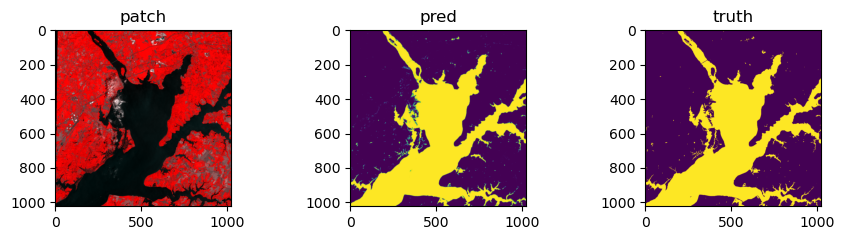

Ep150: tra-> Loss:0.041,Oa:0.985,Miou:0.950,                                 time:39.3s
Ep151: tra-> Loss:0.043,Oa:0.984,Miou:0.946, val-> Loss:0.1199,Oa:0.9582, Miou:0.8832,time:63.2s
Ep152: tra-> Loss:0.041,Oa:0.984,Miou:0.948,                                 time:39.2s
Ep153: tra-> Loss:0.041,Oa:0.984,Miou:0.948, val-> Loss:0.1108,Oa:0.9610, Miou:0.8863,time:63.1s
Ep154: tra-> Loss:0.043,Oa:0.983,Miou:0.946,                                 time:39.2s
Ep155: tra-> Loss:0.045,Oa:0.983,Miou:0.945, val-> Loss:0.1307,Oa:0.9604, Miou:0.8861,time:63.1s
Ep156: tra-> Loss:0.044,Oa:0.983,Miou:0.946,                                 time:39.2s
Ep157: tra-> Loss:0.067,Oa:0.975,Miou:0.921, val-> Loss:0.0930,Oa:0.9672, Miou:0.8988,time:63.1s
Ep158: tra-> Loss:0.050,Oa:0.981,Miou:0.938,                                 time:39.4s
Ep159: tra-> Loss:0.043,Oa:0.983,Miou:0.945, val-> Loss:0.1331,Oa:0.9594, Miou:0.8854,time:63.0s
Ep160: tra-> Loss:0.041,Oa:0.984,Miou:0.947,                               

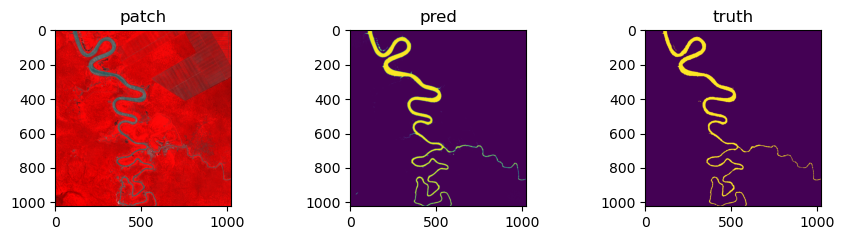

Ep200: tra-> Loss:0.040,Oa:0.985,Miou:0.951,                                 time:39.3s
Ep201: tra-> Loss:0.037,Oa:0.986,Miou:0.954, val-> Loss:0.1275,Oa:0.9597, Miou:0.8863,time:62.9s
Ep202: tra-> Loss:0.039,Oa:0.986,Miou:0.951,                                 time:39.3s
Ep203: tra-> Loss:0.038,Oa:0.985,Miou:0.952, val-> Loss:0.1196,Oa:0.9621, Miou:0.8915,time:63.0s
Ep204: tra-> Loss:0.038,Oa:0.986,Miou:0.953,                                 time:39.3s
Ep205: tra-> Loss:0.035,Oa:0.987,Miou:0.956, val-> Loss:0.1229,Oa:0.9625, Miou:0.8922,time:63.1s
Ep206: tra-> Loss:0.036,Oa:0.986,Miou:0.955,                                 time:39.4s
Ep207: tra-> Loss:0.037,Oa:0.986,Miou:0.954, val-> Loss:0.1440,Oa:0.9597, Miou:0.8865,time:63.0s
Ep208: tra-> Loss:0.038,Oa:0.985,Miou:0.952,                                 time:39.2s
Ep209: tra-> Loss:0.038,Oa:0.986,Miou:0.952, val-> Loss:0.1114,Oa:0.9631, Miou:0.8946,time:63.1s
Ep210: tra-> Loss:0.036,Oa:0.986,Miou:0.955,                               

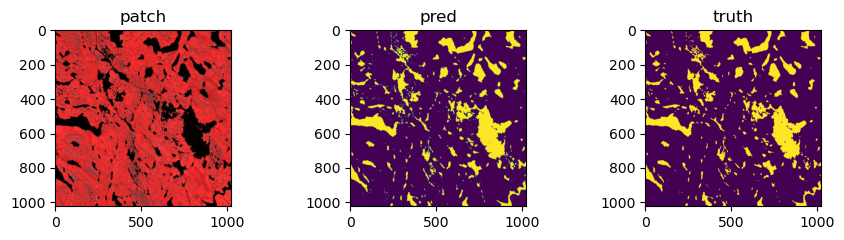

Ep250: tra-> Loss:0.038,Oa:0.986,Miou:0.952,                                 time:39.4s
Ep251: tra-> Loss:0.034,Oa:0.987,Miou:0.956, val-> Loss:0.0888,Oa:0.9674, Miou:0.9038,time:63.1s
Ep252: tra-> Loss:0.033,Oa:0.987,Miou:0.958,                                 time:39.3s
Ep253: tra-> Loss:0.031,Oa:0.988,Miou:0.960, val-> Loss:0.1318,Oa:0.9638, Miou:0.8956,time:63.1s
Ep254: tra-> Loss:0.031,Oa:0.988,Miou:0.962,                                 time:39.2s
Ep255: tra-> Loss:0.032,Oa:0.988,Miou:0.960, val-> Loss:0.1137,Oa:0.9662, Miou:0.9012,time:63.2s
Ep256: tra-> Loss:0.031,Oa:0.988,Miou:0.961,                                 time:39.4s
Ep257: tra-> Loss:0.031,Oa:0.988,Miou:0.961, val-> Loss:0.1365,Oa:0.9648, Miou:0.8979,time:63.2s
Ep258: tra-> Loss:0.030,Oa:0.989,Miou:0.962,                                 time:39.3s
Ep259: tra-> Loss:0.032,Oa:0.987,Miou:0.958, val-> Loss:0.1444,Oa:0.9636, Miou:0.8945,time:63.0s
Ep260: tra-> Loss:0.031,Oa:0.988,Miou:0.959,                               

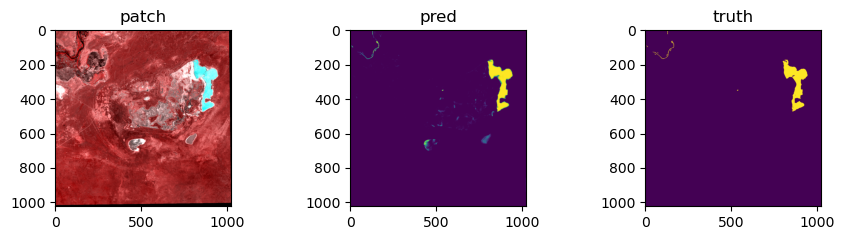

Ep300: tra-> Loss:0.030,Oa:0.988,Miou:0.961,                                 time:39.2s
Ep301: tra-> Loss:0.028,Oa:0.989,Miou:0.963, val-> Loss:0.1954,Oa:0.9612, Miou:0.8896,time:63.1s
Ep302: tra-> Loss:0.029,Oa:0.989,Miou:0.962,                                 time:39.3s
Ep303: tra-> Loss:0.035,Oa:0.987,Miou:0.955, val-> Loss:0.1542,Oa:0.9630, Miou:0.8942,time:63.2s
Ep304: tra-> Loss:0.029,Oa:0.989,Miou:0.962,                                 time:39.3s
Ep305: tra-> Loss:0.029,Oa:0.989,Miou:0.962, val-> Loss:0.1639,Oa:0.9622, Miou:0.8925,time:63.1s
Ep306: tra-> Loss:0.028,Oa:0.989,Miou:0.963,                                 time:39.4s
Ep307: tra-> Loss:0.028,Oa:0.989,Miou:0.962, val-> Loss:0.1398,Oa:0.9632, Miou:0.8941,time:63.2s
Ep308: tra-> Loss:0.031,Oa:0.988,Miou:0.960,                                 time:39.3s
Ep309: tra-> Loss:0.030,Oa:0.988,Miou:0.962, val-> Loss:0.1525,Oa:0.9614, Miou:0.8909,time:63.0s
Ep310: tra-> Loss:0.036,Oa:0.986,Miou:0.955,                               

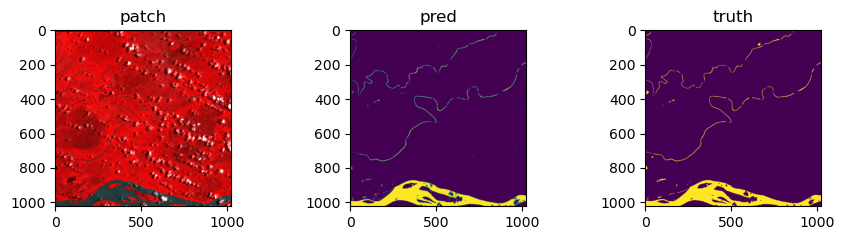

Ep350: tra-> Loss:0.032,Oa:0.988,Miou:0.960,                                 time:39.3s
Ep351: tra-> Loss:0.027,Oa:0.990,Miou:0.966, val-> Loss:0.1425,Oa:0.9628, Miou:0.8933,time:63.1s
Ep352: tra-> Loss:0.025,Oa:0.990,Miou:0.967,                                 time:39.3s
Ep353: tra-> Loss:0.027,Oa:0.989,Miou:0.965, val-> Loss:0.1635,Oa:0.9635, Miou:0.8946,time:63.2s
Ep354: tra-> Loss:0.030,Oa:0.988,Miou:0.962,                                 time:39.3s
Ep355: tra-> Loss:0.034,Oa:0.987,Miou:0.958, val-> Loss:0.1449,Oa:0.9600, Miou:0.8871,time:63.1s
Ep356: tra-> Loss:0.040,Oa:0.984,Miou:0.950,                                 time:39.4s
Ep357: tra-> Loss:0.034,Oa:0.987,Miou:0.958, val-> Loss:0.1337,Oa:0.9613, Miou:0.8898,time:63.1s
Ep358: tra-> Loss:0.032,Oa:0.988,Miou:0.960,                                 time:39.3s
Ep359: tra-> Loss:0.027,Oa:0.990,Miou:0.965, val-> Loss:0.1333,Oa:0.9632, Miou:0.8946,time:63.1s
Ep360: tra-> Loss:0.027,Oa:0.990,Miou:0.964,                               

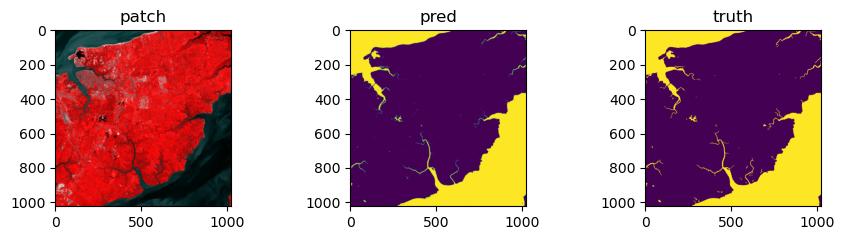

Ep400: tra-> Loss:0.027,Oa:0.989,Miou:0.964,                                 time:39.4s
Ep401: tra-> Loss:0.026,Oa:0.990,Miou:0.967, val-> Loss:0.1276,Oa:0.9620, Miou:0.8918,time:63.1s
Ep402: tra-> Loss:0.026,Oa:0.990,Miou:0.968,                                 time:39.3s
Ep403: tra-> Loss:0.035,Oa:0.987,Miou:0.957, val-> Loss:0.0939,Oa:0.9663, Miou:0.9017,time:63.2s
Ep404: tra-> Loss:0.030,Oa:0.989,Miou:0.962,                                 time:39.3s


In [ ]:
if __name__ == '__main__':
    metrics = train_loops(model=model,  
                    epoches=500,   
                    loss_fn=bce_loss,   
                    optimizer=optimizer,  
                    tra_loader=tra_loader,   
                    val_loader=val_loader,   
                    # lr_scheduler=lr_scheduler,   
                    device=device)   



In [ ]:
# torch.save(model.state_dict(), f'model/trained/{model_name}_.pth')
# ## metrics saving
# path_metrics = f'model/trained/{model_name}_training_metrics.csv'   
# metrics_df = pd.DataFrame(metrics)
# metrics_df.to_csv(path_metrics, index=False, sep=',')  

